In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd

In [3]:
mall = pd.read_csv(r"C:\Users\HP\Downloads\mall_kmeans.csv")

In [4]:
mall.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
mall.drop('CustomerID', axis=1, inplace=True)

In [6]:
mall.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Score'}, inplace=True)

In [7]:
mall['Genre'].replace({'Female': 0, 'Male': 1}, inplace=True)

In [8]:
mall.head()

,Genre,Age,Income,Score
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


In [9]:
from sklearn.cluster import AgglomerativeClustering

In [10]:
agg_mall = AgglomerativeClustering(n_clusters=5, linkage='ward', metric='euclidean')
#mall['Cluster'] = agg_mall.fit_predict(mall)

In [11]:
agg_mall.fit(mall)

,n_clusters,5
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [12]:
agg_mall.labels_

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 0, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 0,
       4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 1, 2, 1, 2, 1, 2,
       0, 2, 1, 2, 1, 2, 1, 2, 1, 2, 0, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2])

In [13]:
len(agg_mall.labels_)

200

In [14]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [15]:
mall['Cluster'] = agg_mall.fit_predict(mall)

In [16]:
mall['Cluster'].value_counts()

Cluster
0    83
2    39
1    35
4    23
3    20
Name: count, dtype: int64

In [17]:
# Features only (excluding cluster labels)
X = mall.drop('Cluster', axis=1)
labels = mall['Cluster']

In [18]:
# Evaluation metrics
sil_score = silhouette_score(X, labels)
sil_score

0.43997527212476695

In [19]:
mall.head()

,Genre,Age,Income,Score,Cluster
0,1,19,15,39,4
1,1,21,15,81,3
2,0,20,16,6,4
3,0,23,16,77,3
4,0,31,17,40,4


In [20]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np

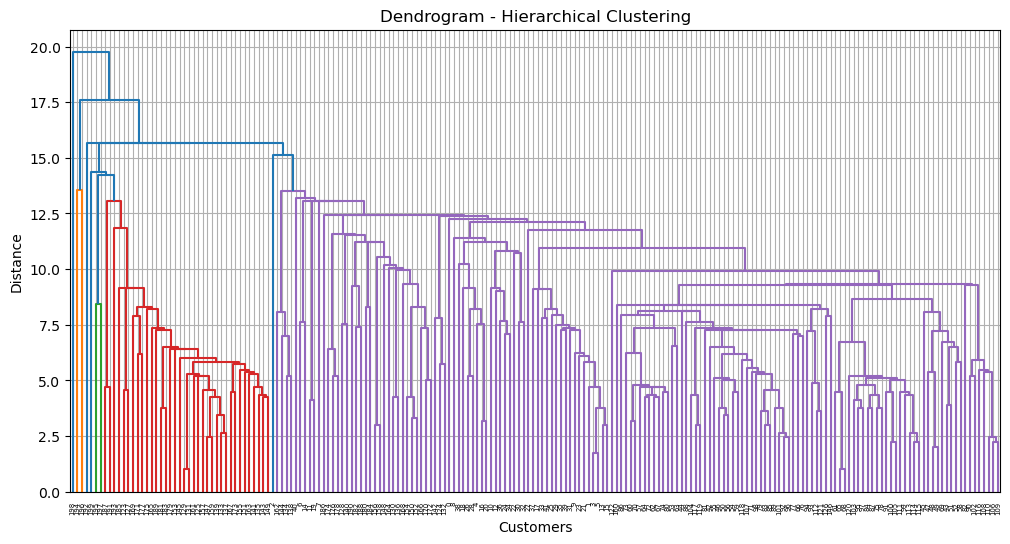

In [21]:
# Dendrogram to help choose number of clusters (optional but useful)
plt.figure(figsize=(12, 6))
link_result = linkage(mall.drop('Cluster', axis=1), method='single')
dendrogram(link_result)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.grid()
plt.show()

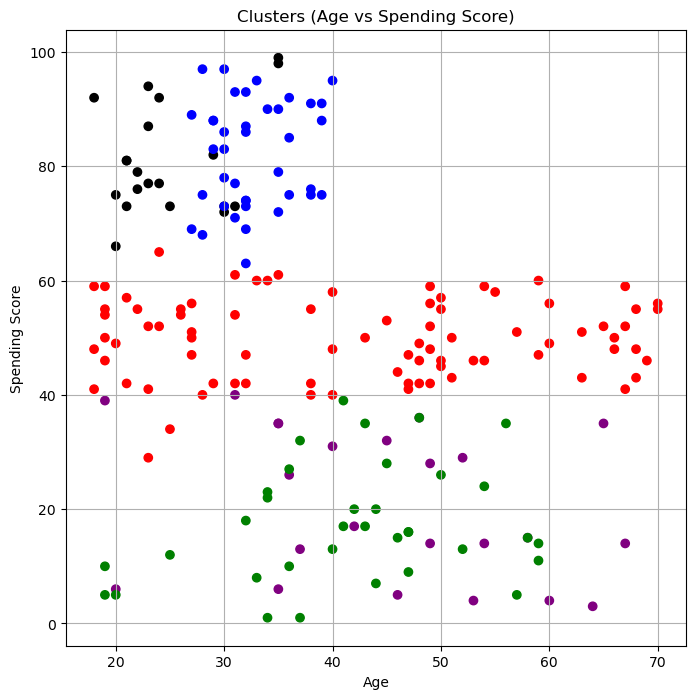

In [22]:
# Scatter plot: Age vs Spending Score colored by cluster
colors = np.array(['red', 'green', 'blue', 'black', 'purple'])

plt.figure(figsize=(8, 8))
plt.scatter(mall['Age'], mall['Score'], c=colors[mall['Cluster']])
plt.title("Clusters (Age vs Spending Score)")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.grid()
plt.show()

# PCA

In [23]:
import pandas as pd

In [24]:
pd.read_csv(r"C:\Users\HP\Downloads\Property_Price_Train.csv.xls")

,Id,Building_Class,Zoning_Class,Lot_Extent,Lot_Size,Road_Type,Lane_Type,Property_Shape,Land_Outline,Utility_Type,...,Pool_Area,Pool_Quality,Fence_Quality,Miscellaneous_Feature,Miscellaneous_Value,Month_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price
0,1,60,RLD,65.0,8450,Paved,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RLD,80.0,9600,Paved,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RLD,68.0,11250,Paved,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RLD,60.0,9550,Paved,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RLD,84.0,14260,Paved,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,1455,20,FVR,62.0,7500,Paved,Paved,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2009,WD,Normal,185000
1455,1456,60,RLD,62.0,7917,Paved,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RLD,85.0,13175,Paved,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RLD,66.0,9042,Paved,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500


In [25]:
pp=pd.read_csv(r"C:\Users\HP\Downloads\Property_Price_Train.csv.xls")

In [26]:
pp.select_dtypes(include='object').columns

Index(['Zoning_Class', 'Road_Type', 'Lane_Type', 'Property_Shape',
       'Land_Outline', 'Utility_Type', 'Lot_Configuration', 'Property_Slope',
       'Neighborhood', 'Condition1', 'Condition2', 'House_Type',
       'House_Design', 'Roof_Design', 'Roof_Quality', 'Exterior1st',
       'Exterior2nd', 'Brick_Veneer_Type', 'Exterior_Material',
       'Exterior_Condition', 'Foundation_Type', 'Basement_Height',
       'Basement_Condition', 'Exposure_Level', 'BsmtFinType1', 'BsmtFinType2',
       'Heating_Type', 'Heating_Quality', 'Air_Conditioning',
       'Electrical_System', 'Kitchen_Quality', 'Functional_Rate',
       'Fireplace_Quality', 'Garage', 'Garage_Finish_Year', 'Garage_Quality',
       'Garage_Condition', 'Pavedd_Drive', 'Pool_Quality', 'Fence_Quality',
       'Miscellaneous_Feature', 'Sale_Type', 'Sale_Condition'],
      dtype='object')

In [27]:
pp.isnull().sum()[pp.isnull().sum()>0]  

Lot_Extent                259
Lane_Type                1368
Brick_Veneer_Type         871
Brick_Veneer_Area           8
Basement_Height            37
Basement_Condition         37
Exposure_Level             38
BsmtFinType1               37
BsmtFinType2               38
Electrical_System           1
Fireplace_Quality         689
Garage                     81
Garage_Built_Year          81
Garage_Finish_Year         81
Garage_Quality             81
Garage_Condition           81
Pool_Quality             1452
Fence_Quality            1178
Miscellaneous_Feature    1405
dtype: int64

In [28]:
pp=pp.drop(['Id','Fireplace_Quality','Pool_Quality','Fence_Quality','Miscellaneous_Feature','Lane_Type'],axis=1)

In [29]:
pp.Lot_Extent.fillna(pp.Lot_Extent.mean(),inplace=True)
#pp.Lane_Type.fillna('Grvl',inplace=True)
pp.Brick_Veneer_Type.fillna('None',inplace=True)
pp.Brick_Veneer_Area.fillna(pp.Brick_Veneer_Area.mean(),inplace=True)
pp.Basement_Height.fillna('TA',inplace=True)
pp.Basement_Condition.fillna('TA',inplace=True)
pp.Exposure_Level.fillna('NO',inplace=True)
pp.BsmtFinType1.fillna('Unf',inplace=True)
pp.BsmtFinType2.fillna('Unf',inplace=True)
pp.Electrical_System.fillna('SBrkr',inplace=True)
#pp.Fireplace_Quality.fillna('Gd',inplace=True)
pp.Garage.fillna('Attchd',inplace=True)
pp.Garage_Built_Year.fillna(pp.Garage_Built_Year.mean(),inplace=True)
pp.Garage_Finish_Year.fillna('Unf',inplace=True)
pp.Garage_Quality.fillna('TA',inplace=True)
pp.Garage_Condition.fillna('TA',inplace=True)

In [30]:
pp.isnull().sum()[pp.isnull().sum()>0]

Series([], dtype: int64)

In [31]:
from sklearn.preprocessing import LabelEncoder

In [32]:
le=LabelEncoder()

pp[pp.select_dtypes(include='object').columns] = pp[pp.select_dtypes(include='object').columns].apply(le.fit_transform)

In [33]:
pp.head()

,Building_Class,Zoning_Class,Lot_Extent,Lot_Size,Road_Type,Property_Shape,Land_Outline,Utility_Type,Lot_Configuration,Property_Slope,...,Enclosed_Lobby_Area,Three_Season_Lobby_Area,Screen_Lobby_Area,Pool_Area,Miscellaneous_Value,Month_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price
0,60,3,65.0,8450,1,3,3,0,4,0,...,20.337934,0,0,0,0,2,2008,8,4,208500
1,20,3,80.0,9600,1,3,3,0,2,0,...,15.039392,0,0,0,0,5,2007,8,4,181500
2,60,3,68.0,11250,1,0,3,0,4,0,...,-46.232198,0,0,0,0,9,2008,8,4,223500
3,70,3,60.0,9550,1,0,3,0,0,0,...,60.921821,0,0,0,0,2,2006,8,0,140000
4,60,3,84.0,14260,1,0,3,0,2,0,...,21.788818,0,0,0,0,12,2008,8,4,250000


In [34]:
pp.columns

Index(['Building_Class', 'Zoning_Class', 'Lot_Extent', 'Lot_Size', 'Road_Type',
       'Property_Shape', 'Land_Outline', 'Utility_Type', 'Lot_Configuration',
       'Property_Slope', 'Neighborhood', 'Condition1', 'Condition2',
       'House_Type', 'House_Design', 'Overall_Material', 'House_Condition',
       'Construction_Year', 'Remodel_Year', 'Roof_Design', 'Roof_Quality',
       'Exterior1st', 'Exterior2nd', 'Brick_Veneer_Type', 'Brick_Veneer_Area',
       'Exterior_Material', 'Exterior_Condition', 'Foundation_Type',
       'Basement_Height', 'Basement_Condition', 'Exposure_Level',
       'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF',
       'Total_Basement_Area', 'Heating_Type', 'Heating_Quality',
       'Air_Conditioning', 'Electrical_System', 'First_Floor_Area',
       'Second_Floor_Area', 'LowQualFinSF', 'Grade_Living_Area',
       'Underground_Full_Bathroom', 'Underground_Half_Bathroom',
       'Full_Bathroom_Above_Grade', 'Half_Bathroom_Above_Grade',


In [35]:
pp1=pp

In [36]:
pp=pp.drop(['Sale_Price'],axis=1)

In [37]:
pp.shape

(1459, 74)

In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [39]:
scaled_pp =scaler.fit_transform(pp)
scaled_pp

array([[ 0.07277097, -0.04554757, -0.22910986, ...,  0.13882596,
         0.31398524,  0.20857685],
       [-0.87308957, -0.04554757,  0.45197643, ..., -0.61413713,
         0.31398524,  0.20857685],
       [ 0.07277097, -0.04554757, -0.0928926 , ...,  0.13882596,
         0.31398524,  0.20857685],
       ...,
       [-0.87308957, -0.04554757,  0.67900519, ...,  1.64475213,
         0.31398524,  0.20857685],
       [ 0.30923611, -0.04554757, -0.18370411, ...,  1.64475213,
         0.31398524,  0.20857685],
       [-0.87308957, -0.04554757, -0.0928926 , ...,  1.64475213,
         0.31398524,  0.20857685]], shape=(1459, 74))

In [40]:
from sklearn import decomposition
from sklearn.decomposition import PCA

In [41]:
pca =PCA(n_components=55)  # create an instance

In [42]:
x_pca1=pca.fit_transform(scaled_pp)
#PCA has been performed

In [43]:
pca.explained_variance_ratio_

array([0.12851673, 0.05356507, 0.0487574 , 0.03934584, 0.03068923,
       0.02776844, 0.02448971, 0.0231181 , 0.02126221, 0.02048941,
       0.02029615, 0.0187846 , 0.01792711, 0.01761655, 0.01707248,
       0.01630691, 0.01587636, 0.01556845, 0.01539727, 0.01517467,
       0.01486929, 0.01417392, 0.01402088, 0.01379118, 0.01372866,
       0.01341276, 0.01314542, 0.0130173 , 0.01265897, 0.01254572,
       0.0121647 , 0.01152965, 0.01144495, 0.01121828, 0.01085052,
       0.01047954, 0.01020399, 0.01010287, 0.00990957, 0.00951179,
       0.00920503, 0.0090012 , 0.00894737, 0.00860479, 0.00846629,
       0.00801367, 0.00788154, 0.00753056, 0.00718028, 0.00682004,
       0.00630137, 0.00622734, 0.00608672, 0.00579034, 0.00563004])

In [44]:
l1=list(pca.explained_variance_ratio_)

In [45]:
len(l1)

55

In [46]:
pca.explained_variance_ratio_.sum()

np.float64(0.942489242394302)

In [47]:
import numpy as np

In [48]:
np.sum(l1[0:55])

np.float64(0.942489242394302)

In [49]:
df=pd.DataFrame(x_pca1[:,0:55])

In [50]:
from sklearn.linear_model import LinearRegression
linreg =LinearRegression()

In [51]:
linreg.fit(df,pp1.Sale_Price)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [52]:
linreg.score(df,pp1.Sale_Price)

0.8488711700027833

In [53]:
df1=pd.DataFrame(x_pca1)

In [54]:
df1.corr().round(3)

,0,1,2,3,4,5,6,7,8,9,...,45,46,47,48,49,50,51,52,53,54
0,1.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,...,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0
1,-0.0,1.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,...,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0
2,-0.0,0.0,1.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,...,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0
3,0.0,0.0,0.0,1.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,...,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0
4,-0.0,0.0,-0.0,-0.0,1.0,0.0,-0.0,-0.0,0.0,-0.0,...,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0
5,-0.0,-0.0,-0.0,-0.0,0.0,1.0,-0.0,-0.0,-0.0,-0.0,...,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0
6,0.0,-0.0,-0.0,0.0,-0.0,-0.0,1.0,-0.0,0.0,-0.0,...,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0
7,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,1.0,-0.0,0.0,...,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0
8,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,1.0,0.0,...,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0
9,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,1.0,...,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0


In [55]:
pp.shape

(1459, 74)

In [56]:
pp1.shape

(1459, 75)